Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
          VISIONPORT OBJECT DETECTION SYSTEM
Project       : VisionPort
Skill         : SKILL_1
Model         : YOLOv8n
Framework     : Ultralytics
Application   : Deep Learning Object Detection

STEP 1: IMAGE ACQUISITION
--------------------------------------------------
Please upload a real photograph...


Saving images (3).jpg to images (3).jpg
Image uploaded successfully!
Image Name: images (3).jpg

STEP 2: MODEL LOADING
--------------------------------------------------
Loading YOLOv8 pretrained model...
YOLOv8 model loaded successfully!
Model Variant: YOLOv8 Nano

STEP 3: IMAGE PREPROCESSING
--------------------------------------------------
Image preprocessing completed!
Image Width  : 554
Image Height : 554
Channels     : 3
Image Shape  : (554, 554, 3)

STEP 4: OBJECT DETECTION
--------------------------------------------------
Performing YOLOv8 object detection...
Object detection inference completed!

STEP 5: BOUNDING BOX GENERATION
--------------------------------------------------
Bounding boxes generated successfully!

STEP 6: OBJECT DETECTION RESULTS

Object 1: couch
Confidence    : 67.92%
Bounding Box  : (0, 248, 280, 551)

Object 2: vase
Confidence    : 50.17%
Bounding Box  : (391, 118, 420, 178)

Object 3: vase
Confidence    : 45.59%
Bounding Box  : (372, 97, 393, 179)

Ob

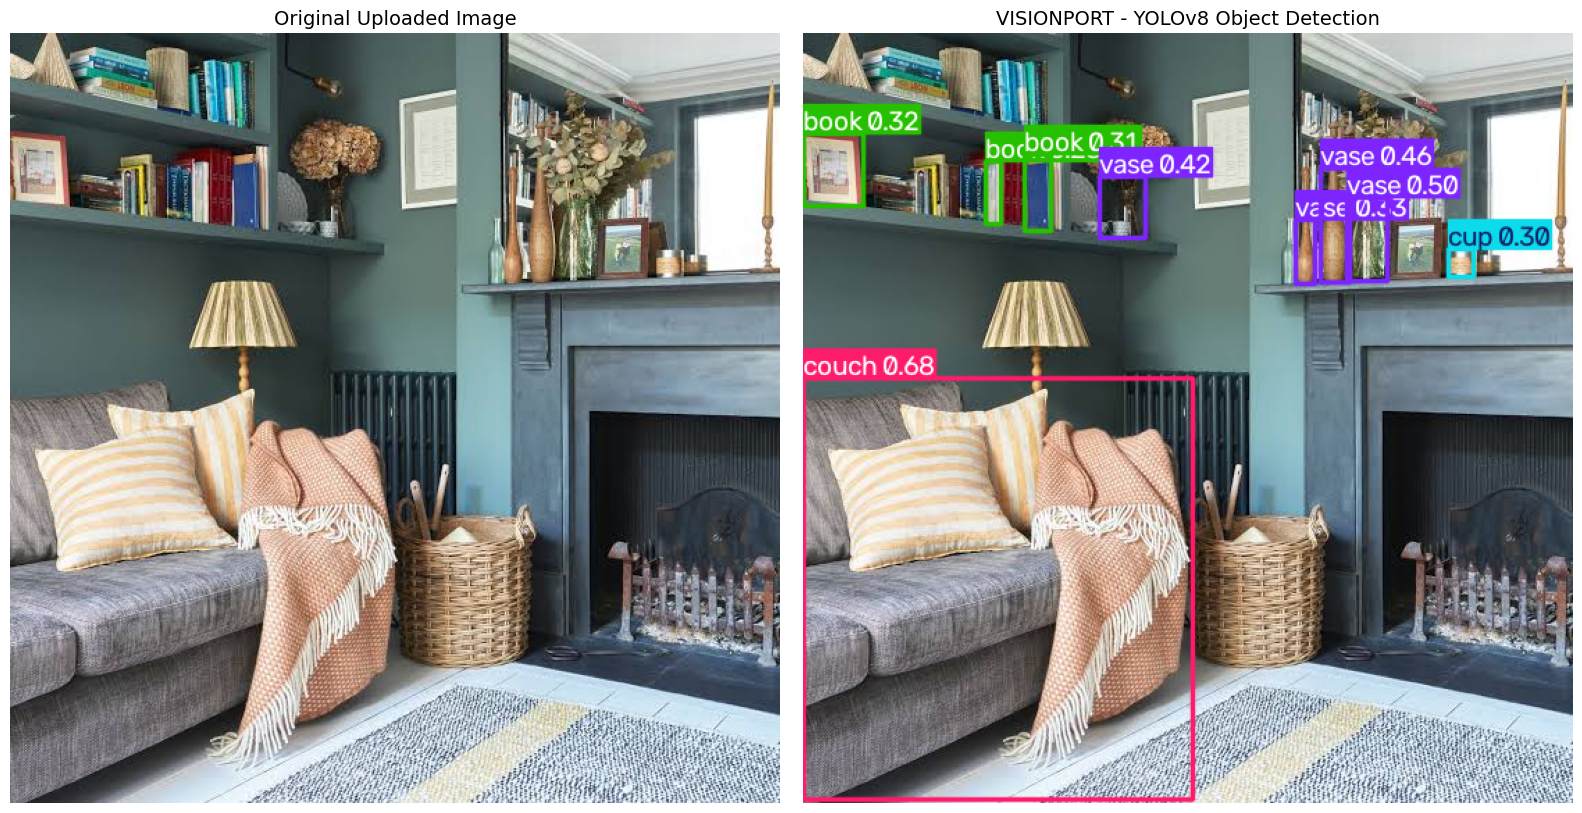

Image visualization completed!

STEP 9: OUTPUT GENERATION
--------------------------------------------------
Detection output saved successfully!
Output File: VisionPort_Detection_Output.jpg


              VISIONPORT SYSTEM REPORT
Project Name            : VisionPort
Model Architecture      : YOLOv8
Model Variant           : YOLOv8n
Framework               : Ultralytics
Confidence Threshold    : 0.25
Input Image Size        : 640
-----------------------------------------------------------------
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation : SUCCESS
Object Classification  : SUCCESS
Object Counting         : SUCCESS
Output Visualization    : SUCCESS
Output Image Saving     : SUCCESS
-----------------------------------------------------------------
Total Objects Detected  : 9
VISIONPORT PIPELINE COMPLETED SUCCESSFULLY!



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VISIONPORT EXPERIMENT COMPLETED!


In [1]:
# ============================================================
# VISIONPORT - DEEP LEARNING OBJECT DETECTION SYSTEM
# SKILL_1: Project Orientation and Lifecycle Mapping
# Model: YOLOv8
# Framework: Ultralytics
# Environment: Google Colab
# ============================================================


# 1. INSTALL REQUIRED LIBRARY

!pip install -q ultralytics


# 2. IMPORT REQUIRED LIBRARIES

import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

from collections import Counter
import os


# 3. DISPLAY PROJECT INFORMATION

print("=" * 65)
print("          VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 65)

print("Project       : VisionPort")
print("Skill         : SKILL_1")
print("Model         : YOLOv8n")
print("Framework     : Ultralytics")
print("Application   : Deep Learning Object Detection")

print("=" * 65)


# 4. IMAGE ACQUISITION - UPLOAD REAL IMAGE

print("\nSTEP 1: IMAGE ACQUISITION")
print("-" * 50)

print("Please upload a real photograph...")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded!")

image_path = list(uploaded.keys())[0]

print("Image uploaded successfully!")
print("Image Name:", image_path)


# 5. LOAD PRETRAINED YOLOv8 MODEL

print("\nSTEP 2: MODEL LOADING")
print("-" * 50)

print("Loading YOLOv8 pretrained model...")

model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")
print("Model Variant: YOLOv8 Nano")


# 6. IMAGE PREPROCESSING

print("\nSTEP 3: IMAGE PREPROCESSING")
print("-" * 50)

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width, channels = image_rgb.shape

print("Image preprocessing completed!")
print("Image Width  :", width)
print("Image Height :", height)
print("Channels     :", channels)
print("Image Shape  :", image_rgb.shape)


# 7. OBJECT DETECTION - MODEL INFERENCE

print("\nSTEP 4: OBJECT DETECTION")
print("-" * 50)

print("Performing YOLOv8 object detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)

print("Object detection inference completed!")


# 8. BOUNDING BOX GENERATION

print("\nSTEP 5: BOUNDING BOX GENERATION")
print("-" * 50)

output_image = results[0].plot()

output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

print("Bounding boxes generated successfully!")


# 9. DISPLAY DETECTION RESULTS

print("\nSTEP 6: OBJECT DETECTION RESULTS")
print("=" * 60)

boxes = results[0].boxes

detected_objects = []

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):

        class_id = int(box.cls[0])

        confidence = float(box.conf[0])

        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].tolist()
        )

        detected_objects.append(object_name)

        print(f"\nObject {i + 1}: {object_name}")
        print(f"Confidence    : {confidence * 100:.2f}%")
        print(f"Bounding Box  : ({x1}, {y1}, {x2}, {y2})")

else:

    print("No objects detected in the uploaded image.")


# 10. OBJECT COUNTING

print("\nSTEP 7: OBJECT COUNTING")
print("-" * 50)

total_objects = len(detected_objects)

print("Total Objects Detected:", total_objects)

if detected_objects:

    object_counts = Counter(detected_objects)

    print("\nObject Category Summary:")

    for name, count in object_counts.items():

        print(f"{name}: {count}")


# 11. VISUALIZATION - ORIGINAL VS DETECTED IMAGE

print("\nSTEP 8: OUTPUT VISUALIZATION")
print("-" * 50)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)

plt.imshow(image_rgb)

plt.title(
    "Original Uploaded Image",
    fontsize=14
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(output_image)

plt.title(
    "VISIONPORT - YOLOv8 Object Detection",
    fontsize=14
)

plt.axis("off")

plt.tight_layout()

plt.show()

print("Image visualization completed!")


# 12. SAVE DETECTED IMAGE

print("\nSTEP 9: OUTPUT GENERATION")
print("-" * 50)

output_path = "VisionPort_Detection_Output.jpg"

success = cv2.imwrite(
    output_path,
    cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)
)

if not success:
    raise IOError("Failed to save the output image!")

print("Detection output saved successfully!")
print("Output File:", output_path)


# 13. FINAL SYSTEM REPORT

print("\n")
print("=" * 65)
print("              VISIONPORT SYSTEM REPORT")
print("=" * 65)

print("Project Name            : VisionPort")
print("Model Architecture      : YOLOv8")
print("Model Variant           : YOLOv8n")
print("Framework               : Ultralytics")
print("Confidence Threshold    : 0.25")
print("Input Image Size        : 640")

print("-" * 65)

print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")

if total_objects > 0:
    print("Object Detection        : SUCCESS")
else:
    print("Object Detection        : NO OBJECTS DETECTED")

print("Bounding Box Generation : SUCCESS")
print("Object Classification  : SUCCESS")
print("Object Counting         : SUCCESS")
print("Output Visualization    : SUCCESS")
print("Output Image Saving     : SUCCESS")

print("-" * 65)

print("Total Objects Detected  :", total_objects)

print("=" * 65)

print("VISIONPORT PIPELINE COMPLETED SUCCESSFULLY!")

print("=" * 65)


# 14. DOWNLOAD DETECTION OUTPUT

print("\nDownloading detection output...")

files.download(output_path)

print("VISIONPORT EXPERIMENT COMPLETED!")